All 311 complaints in January 2026: 348510
problem
HEAT/HOT WATER          79928
Illegal Parking         48717
Noise - Residential     28739
Snow or Ice             24079
Blocked Driveway        17407
UNSANITARY CONDITION    10961
PLUMBING                 8695
Water System             6292
PAINT/PLASTER            6029
DOOR/WINDOW              5465
Name: count, dtype: int64

Illegal Parking is 14.0 % of all complaints


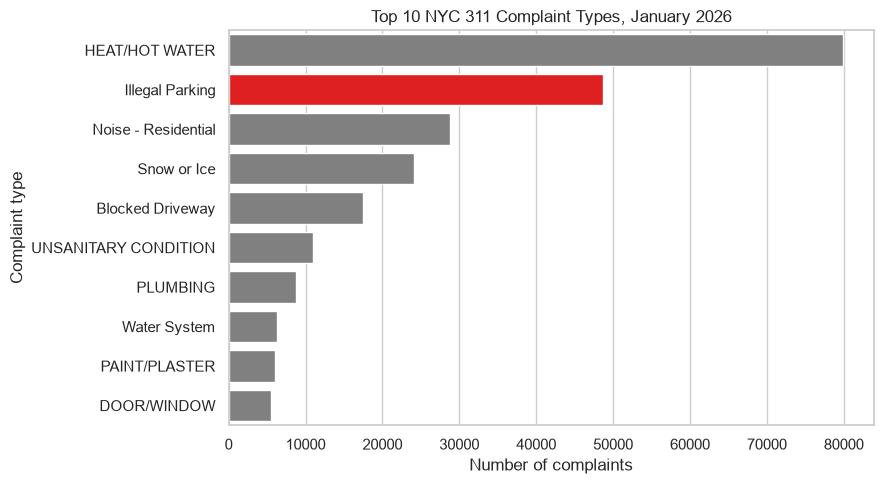

HEAT/HOT WATER -> HPD ( 79928 of 79928 )
Illegal Parking -> NYPD ( 48717 of 48717 )
Noise - Residential -> NYPD ( 28739 of 28739 )
Snow or Ice -> DSNY ( 24079 of 24079 )
Blocked Driveway -> NYPD ( 17407 of 17407 )
UNSANITARY CONDITION -> HPD ( 10961 of 10961 )
PLUMBING -> HPD ( 8695 of 8695 )
Water System -> DEP ( 6292 of 6292 )
PAINT/PLASTER -> HPD ( 6029 of 6029 )
DOOR/WINDOW -> HPD ( 5465 of 5465 )
Illegal Parking complaints: 48717
Missing closed dates: 0
Negative hours: 0
Missing zip codes: 0
Missing latitude/longitude: 321
Rows left: 48715
HOURS TO CLOSE AN ILLEGAL PARKING COMPLAINT
Number of complaints: 48715
Mean:                 2.41
Median:               1.42
Standard deviation:   2.88
Minimum:              0.0
Maximum:              56.33

BOROUGH
               count  percent
borough                      
BROOKLYN       20386     41.8
QUEENS         15290     31.4
BRONX           6924     14.2
MANHATTAN       4647      9.5
STATEN ISLAND   1468      3.0

DETAIL
               

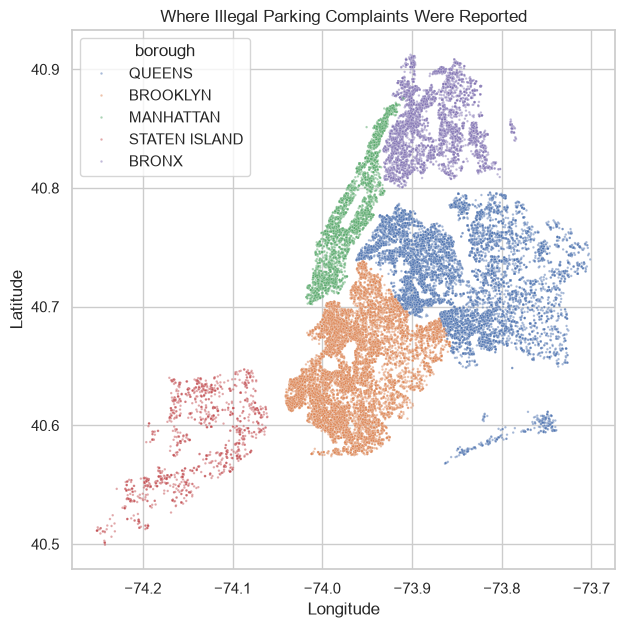

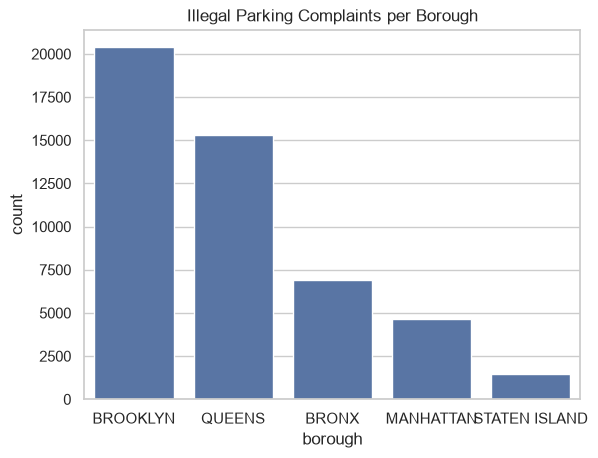

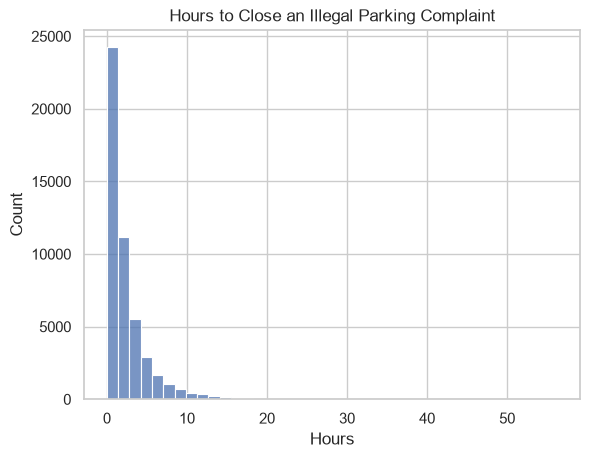

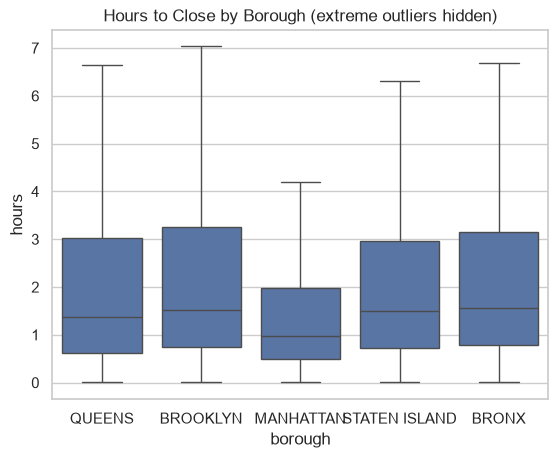

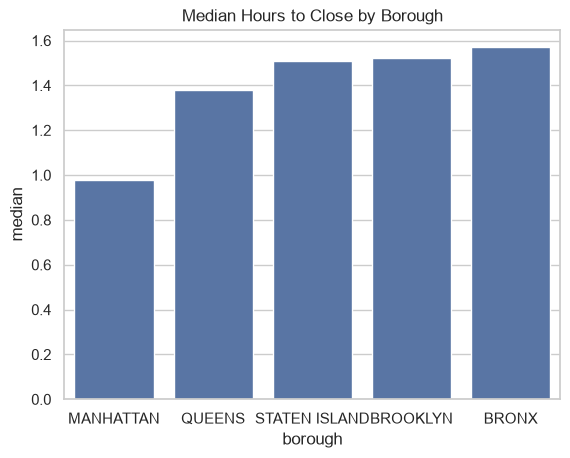

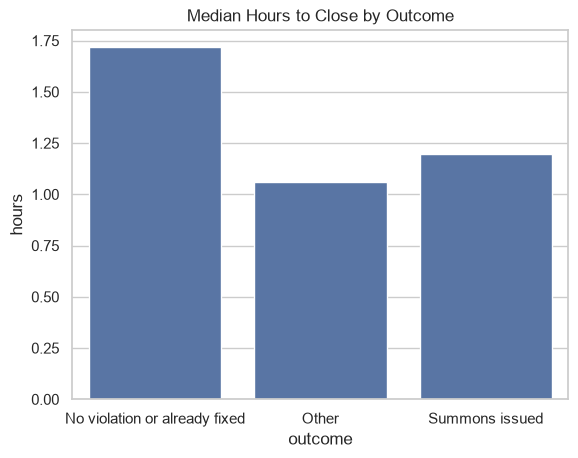

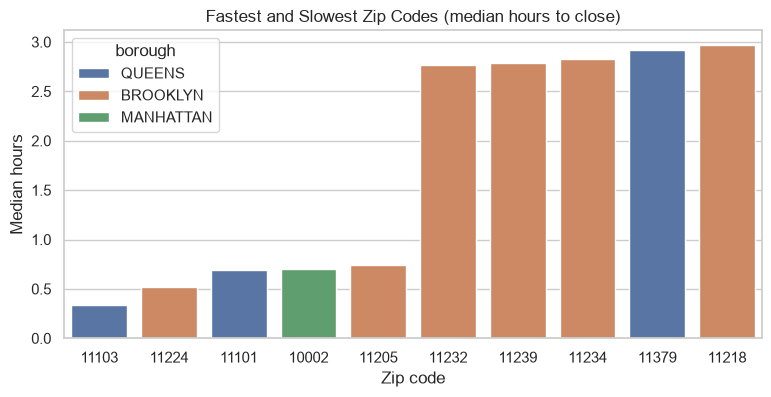

In [10]:
# ============ 1. LOAD THE DATA ============
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("data.csv")

# Keep only the columns we need, with short names
df = df[["Created Date", "Closed Date", "Agency", "Problem (formerly Complaint Type)",
         "Problem Detail (formerly Descriptor)", "Borough", "Incident Zip",
         "Open Data Channel Type", "Resolution Description", "Latitude", "Longitude"]]
df.columns = ["created", "closed", "agency", "problem", "detail",
              "borough", "zip", "channel", "resolution", "latitude", "longitude"]

print("All 311 complaints in January 2026:", len(df))


# ============ 2. TOP 10 COMPLAINTS (ALL COMPLAINT TYPES) ============
# This is why we picked Illegal Parking: it is one of the biggest complaint types.
top10 = df["problem"].value_counts().head(10)
print(top10)
print()
print("Illegal Parking is", round(top10["Illegal Parking"] / len(df) * 100, 1), "% of all complaints")

# Draw the bar chart. Illegal Parking is red, the others are gray.
colors = ["red" if name == "Illegal Parking" else "gray" for name in top10.index]
plt.figure(figsize=(9, 5))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette=colors, legend=False)
plt.title("Top 10 NYC 311 Complaint Types, January 2026")
plt.xlabel("Number of complaints")
plt.ylabel("Complaint type")
plt.tight_layout()
plt.show()


# ============ 3. WHO HANDLES THE TOP COMPLAINTS? ============
# Each top complaint is handled by which agency?
for name in top10.index:
    agencies = df[df["problem"] == name]["agency"].value_counts()
    print(name, "->", agencies.index[0], "(", agencies.iloc[0], "of", top10[name], ")")


# ============ 4. FILTER TO ILLEGAL PARKING ============
df = df[df["problem"] == "Illegal Parking"]
print("Illegal Parking complaints:", len(df))


# ============ 5. CLEAN ============
# Convert the dates from text to real dates
date_format = "%m/%d/%Y %I:%M:%S %p"
df["created"] = pd.to_datetime(df["created"], format=date_format)
df["closed"] = pd.to_datetime(df["closed"], format=date_format)

# New column: hours between created and closed
df["hours"] = (df["closed"] - df["created"]).dt.total_seconds() / 3600

# Remove the 2 rows where the borough is "Unspecified"
df = df[df["borough"] != "Unspecified"]

# Check for problems
print("Missing closed dates:", df["closed"].isna().sum())
print("Negative hours:", (df["hours"] < 0).sum())
print("Missing zip codes:", df["zip"].isna().sum())
print("Missing latitude/longitude:", df["latitude"].isna().sum())

# Zip codes were stored as decimals (like 11218.0). Make them whole numbers.
df["zip"] = df["zip"].astype(int)
print("Rows left:", len(df))


# ============ 6. WHICH AGENCY HANDLES THIS COMPLAINT? ============
df["agency"].value_counts()


# ============ 7. DESCRIPTIVE STATISTICS: HOURS TO CLOSE (ALL ILLEGAL PARKING) ============
print("HOURS TO CLOSE AN ILLEGAL PARKING COMPLAINT")
print("Number of complaints:", len(df))
print("Mean:                ", round(df["hours"].mean(), 2))
print("Median:              ", round(df["hours"].median(), 2))
print("Standard deviation:  ", round(df["hours"].std(), 2))
print("Minimum:             ", round(df["hours"].min(), 2))
print("Maximum:             ", round(df["hours"].max(), 2))
print()
df["hours"].describe().round(2)


# ============ 8. DESCRIPTIVE STATISTICS: HOURS TO CLOSE BY BOROUGH ============
# One row per borough: count, mean, std (standard deviation), min, 25%, median (50%), 75%, max
by_borough = df.groupby("borough")["hours"].describe().round(2)
by_borough = by_borough.rename(columns={"50%": "median"}).sort_values("median")
by_borough["count"] = by_borough["count"].astype(int)   # show counts as whole numbers
by_borough


# ============ 9. DESCRIPTIVE STATISTICS: CATEGORY COUNTS ============
# How many complaints (and what percent) fall in each category
for col in ["borough", "detail", "channel"]:
    counts = df[col].value_counts()
    percent = (df[col].value_counts(normalize=True) * 100).round(1)
    print(col.upper())
    print(pd.DataFrame({"count": counts, "percent": percent}))
    print()


# ============ 10. COMPARE NEIGHBORHOODS (ZIP CODES) ============
# For each zip code: number of complaints, median hours to close, and its borough.
# We only keep zip codes with at least 200 complaints (small groups are unreliable).
by_zip = df.groupby("zip").agg(count=("hours", "count"),
                               median=("hours", "median"),
                               borough=("borough", "first")).round(2)
by_zip = by_zip[by_zip["count"] >= 200].sort_values("median")

print("Zip codes with at least 200 complaints:", len(by_zip))
print()
print("FASTEST 5 ZIP CODES")
print(by_zip.head(5))
print()
print("SLOWEST 5 ZIP CODES")
print(by_zip.tail(5))


# ============ 11. HOW WAS EACH COMPLAINT RESOLVED? ============
# Sort the long resolution text into 3 simple groups.
# "No violation or already fixed" = officers found no violation, or the car was gone/moved by the time they arrived.
df["outcome"] = "Other"
df.loc[df["resolution"].str.contains("summons", na=False), "outcome"] = "Summons issued"
df.loc[df["resolution"].str.contains("no criminal|no evidence", na=False), "outcome"] = "No violation or already fixed"

print((df["outcome"].value_counts(normalize=True) * 100).round(1))
print()
df.groupby("outcome")["hours"].agg(["count", "median"]).round(2)


# ============ 12. MEDIAN HOURS BY HOW THE COMPLAINT WAS SUBMITTED ============
df.groupby("channel")["hours"].agg(["count", "median"]).round(2)


# ============ 13. PLOTS ============
# Plot 1: MAP of where Illegal Parking complaints were reported
# (each dot is one complaint; longitude is left-right, latitude is up-down)
map_data = df.dropna(subset=["latitude", "longitude"])
plt.figure(figsize=(7, 7))
sns.scatterplot(data=map_data, x="longitude", y="latitude", hue="borough", s=3, alpha=0.5)
plt.title("Where Illegal Parking Complaints Were Reported")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# Plot 2: number of complaints per borough
sns.countplot(data=df, x="borough", order=df["borough"].value_counts().index)
plt.title("Illegal Parking Complaints per Borough")
plt.show()

# Plot 3: histogram of hours to close
sns.histplot(df["hours"], bins=40)
plt.title("Hours to Close an Illegal Parking Complaint")
plt.xlabel("Hours")
plt.show()

# Plot 4: box plot of hours by borough (showfliers=False hides the extreme outliers so the boxes are readable)
sns.boxplot(data=df, x="borough", y="hours", showfliers=False)
plt.title("Hours to Close by Borough (extreme outliers hidden)")
plt.show()

# Plot 5: median hours by borough
sns.barplot(data=by_borough.reset_index(), x="borough", y="median")
plt.title("Median Hours to Close by Borough")
plt.show()

# Plot 6: median hours by how the complaint was resolved
by_outcome = df.groupby("outcome")["hours"].median().reset_index()
sns.barplot(data=by_outcome, x="outcome", y="hours")
plt.title("Median Hours to Close by Outcome")
plt.show()

# Plot 7: the 5 fastest and 5 slowest zip codes, colored by borough
extremes = pd.concat([by_zip.head(5), by_zip.tail(5)]).reset_index()
extremes["zip"] = extremes["zip"].astype(str)
plt.figure(figsize=(9, 4))
sns.barplot(data=extremes, x="zip", y="median", hue="borough", dodge=False)
plt.title("Fastest and Slowest Zip Codes (median hours to close)")
plt.xlabel("Zip code")
plt.ylabel("Median hours")
plt.show()